# Avance 1 y Avance 2 — EDA, preprocesamiento y primeros modelos · Carlos Vizcaino y Diego Reyes
**Proyecto Integrador DATA STARTUP · MineTrac · Cliente: Máquinas Centella S.A. de C.V.**
Carlos Alejandro Vizcaino Anguiano · Diego Reyes Natilla · TecNM Colima, Ingeniería en Inteligencia Artificial · Noviembre de 2026

Este cuaderno junta el **Avance 1** (secciones 1 a 9: análisis exploratorio) y el **Avance 2** (secciones 10 a 15: preprocesamiento, partición de datos, entrenamiento de 4 modelos y tabla comparativa).

Repositorio: https://github.com/Carlosvzc/data-startup-minetrac (carpeta `notebooks/`; módulo de construcción del dataset en `services/worker/dataset_riesgo.py`).

## 1. Definición del problema
**Pregunta de negocio.** Cuando un equipo de Máquinas Centella entra a taller por una falla en un sistema (motor, tren motriz y frenos, eléctrico/A-C, estructura, llantas), ¿volverá a registrar una falla en *ese mismo sistema* en los siguientes 30 días?

**Variable objetivo:** `repite_30d` (binaria, **clasificación**). Vale 1 si el mismo equipo registra otra intervención en el mismo sistema entre 1 y 30 días después; 0 si no. Se construye solo mirando hacia adelante en el tiempo, y queda vacía (no se usa) para servicios preventivos, registros sin clasificar, registros sin fecha y los últimos 30 días de datos (aún no se puede saber).

**Justificación y valor práctico.** La empresa lleva su mantenimiento a mano y reacciona a cada falla. Una falla que se repite en un mes suele indicar una reparación incompleta o una pieza que sigue en riesgo. Anticiparla permite: (a) apartar la refacción antes de que el equipo vuelva a parar, (b) priorizar revisión de seguimiento en el taller y (c) reducir horas de máquina detenida. Las variables explicativas son solo información disponible *antes* del momento de decisión (historial previo del equipo, sistema, tipo de equipo, mes), por lo que el modelo sería utilizable en la práctica.

In [1]:
import sys, warnings; warnings.filterwarnings('ignore')
sys.path.insert(0, '../services/worker')
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from scipy import stats
from dataset_riesgo import construir_dataset
plt.rcParams.update({'figure.dpi':110,'axes.spines.top':False,'axes.spines.right':False,'axes.grid':True,'grid.alpha':.25})
AZ,NA,GR='#1f4e79','#d9822b','#7f7f7f'
mant = pd.read_csv('../data/clean/mantenimiento.csv')
lib  = pd.read_csv('../data/clean/libreta_eventos.csv')  # otros equipos: fuera del alcance actual
# Alcance actual: solo camiones. El dataset conserva `fuente` y `equipo_id` para sumar otros equipos después.
df = construir_dataset(mant, lib.iloc[0:0])
df.to_csv('../data/clean/dataset_avance1.csv', index=False)
print(df.shape)
df.head()

(317, 18)


,fuente,equipo_id,tipo_equipo,fecha,fecha_calidad,sistema_original,monto_mxn,pieza_declarada,proveedor_declarado,es_servicio,intervalo_servicio_h,sistema,mes,dia_semana,dias_desde_previo_equipo,registros_previos_90d,previos_mismo_sistema_90d,repite_30d
0,bitacora_camiones,C1,Camión,2023-08-04,ok,"Caja, frenos y suspensión neumática",NaN,0,0,0,NaN,tren_motriz_frenos,8.0,4.0,NaN,0.0,0.0,0.0
1,bitacora_camiones,C1,Camión,2024-04-15,ok,Estético y cabina,NaN,0,0,0,NaN,estructura_cabina,4.0,0.0,255.0,0.0,0.0,1.0
2,bitacora_camiones,C1,Camión,2024-05-15,ok,Estético y cabina,NaN,0,0,0,NaN,estructura_cabina,5.0,2.0,30.0,1.0,1.0,0.0
3,bitacora_camiones,C1,Camión,2024-07-15,ok,A/C y eléctrico,2500.0,0,1,0,NaN,electrico_ac,7.0,0.0,61.0,1.0,0.0,0.0
4,bitacora_camiones,C1,Camión,2024-09-11,ok,"Caja, frenos y suspensión neumática",NaN,0,0,0,NaN,tren_motriz_frenos,9.0,2.0,58.0,1.0,0.0,1.0


## 2. Conjunto de datos
Datos reales de Máquinas Centella: la bitácora de reparaciones de sus **7 camiones** (C1 a C7), llevada a mano por la empresa. Por indicación de la empresa, autorizada por los profesores, el alcance actual es solo camiones. Cada fila es una intervención en un sistema del camión (motor, tren motriz y frenos, eléctrico y A/C, estructura y cabina, llantas). El dataset conserva las columnas `fuente` y `equipo_id`, y el código que lo construye acepta otros equipos, de modo que el resto de la flota (cargadores, minicargadores, etc.) se pueda agregar después sin rehacer el análisis. Las fechas de solo año se dejan vacías en vez de inventarse.

**Nota sobre el tamaño:** con solo camiones hay **317 registros** (284 con etiqueta para el modelo), por debajo del mínimo de 500 de la guía. Es consecuencia del alcance autorizado. En compensación, el periodo cubierto es largo (agosto de 2023 a octubre de 2026, unos 38 meses).

### Alcance del análisis y cómo se amplía
**Este avance usa solo los 7 camiones de Máquinas Centella.** Fue una indicación de la empresa, autorizada por los profesores: por ahora el proyecto se concentra en los camiones.

El dataset está preparado para crecer sin rehacer el análisis:
- Cada fila trae `equipo_id`, `tipo_equipo` y `fuente`, así que sumar cargadores, minicargadores o la retroexcavadora es agregar filas con esos mismos campos.
- Las variables explicativas no dependen del tipo de equipo: se calculan por equipo y por sistema (historial previo, días desde la intervención anterior, mes, monto).
- La función `construir_dataset` (en `services/worker/dataset_riesgo.py`) recibe las tablas de bitácora de cualquier equipo; hoy se le pasa solo la de camiones, y la del resto de la flota se incorporará cuando haya tiempo de capturarla.
- Todo este notebook se vuelve a ejecutar de principio a fin con los datos ampliados; los cuadros, las gráficas y las conclusiones se actualizan solos.

In [2]:
print('Variables explicativas: 9 (sistema, equipo_id, mes, dia_semana, dias_desde_previo_equipo, registros_previos_90d, previos_mismo_sistema_90d, monto_mxn, proveedor_declarado)')
n_lab = df.repite_30d.notna().sum()
print(f'Registros totales: {len(df)}  |  con etiqueta (usables para el modelo): {n_lab}')
print(f'Rango de fechas: {df.fecha.min()} a {df.fecha.max()}')
print(df.fuente.value_counts().to_string())
dic = pd.DataFrame([
 ('fuente','categórica','Origen del registro'),
 ('equipo_id','categórica','Identificador del equipo'),
 ('tipo_equipo','categórica','Tipo de equipo (hoy solo camión)'),
 ('sistema','categórica','Sistema afectado (7 grupos)'),
 ('mes','numérica','Mes de la intervención'),
 ('dia_semana','numérica','Día de la semana (0 = lunes)'),
 ('dias_desde_previo_equipo','numérica','Días desde la intervención anterior del mismo equipo'),
 ('registros_previos_90d','numérica','Intervenciones del equipo en los 90 días previos'),
 ('previos_mismo_sistema_90d','numérica','Intervenciones previas del mismo sistema en 90 días'),
 ('monto_mxn','numérica','Costo declarado (MXN, repartido entre sistemas); disponible en ~30% de los registros'),
 ('proveedor_declarado','binaria','Se anotó proveedor'),
 ('repite_30d','binaria (objetivo)','Misma falla en el mismo equipo en 1–30 días')],
 columns=['variable','tipo','descripción'])
dic

Variables explicativas: 9 (sistema, equipo_id, mes, dia_semana, dias_desde_previo_equipo, registros_previos_90d, previos_mismo_sistema_90d, monto_mxn, proveedor_declarado)
Registros totales: 317  |  con etiqueta (usables para el modelo): 284
Rango de fechas: 2023-08-04 00:00:00 a 2026-10-14 00:00:00
fuente
bitacora_camiones    317


,variable,tipo,descripción
0,fuente,categórica,Origen del registro
1,equipo_id,categórica,Identificador del equipo
2,tipo_equipo,categórica,Tipo de equipo (hoy solo camión)
3,sistema,categórica,Sistema afectado (7 grupos)
4,mes,numérica,Mes de la intervención
5,dia_semana,numérica,Día de la semana (0 = lunes)
6,dias_desde_previo_equipo,numérica,Días desde la intervención anterior del mismo ...
7,registros_previos_90d,numérica,Intervenciones del equipo en los 90 días previos
8,previos_mismo_sistema_90d,numérica,Intervenciones previas del mismo sistema en 90...
9,monto_mxn,numérica,"Costo declarado (MXN, repartido entre sistemas..."


## 3. Estadística descriptiva

In [3]:
num = ['monto_mxn','dias_desde_previo_equipo','registros_previos_90d','previos_mismo_sistema_90d','mes','dia_semana']
d = df[num].describe().T
d['mediana'] = df[num].median()
d['IQR'] = df[num].quantile(.75) - df[num].quantile(.25)
d['asimetría'] = df[num].skew()
d['CV'] = d['std']/d['mean']
d[['count','mean','mediana','std','IQR','min','max','asimetría','CV']].round(2)

,count,mean,mediana,std,IQR,min,max,asimetría,CV
monto_mxn,96.0,9675.33,5100.0,13424.04,8050.0,233.33,74500.0,2.97,1.39
dias_desde_previo_equipo,306.0,27.84,15.0,43.37,22.0,1.00,284.0,3.54,1.56
registros_previos_90d,316.0,5.94,6.0,4.09,6.0,0.00,20.0,0.53,0.69
previos_mismo_sistema_90d,316.0,1.84,1.0,2.11,3.0,0.00,10.0,1.37,1.15
mes,316.0,6.23,6.0,2.91,4.0,1.00,12.0,0.14,0.47
dia_semana,316.0,1.97,2.0,1.48,2.0,0.00,6.0,0.39,0.76


In [4]:
for c in ['equipo_id','sistema']:
    t = df[c].value_counts().to_frame('n'); t['%'] = (100*t.n/len(df)).round(1); print(t, '\n')
print('Balance del objetivo (registros etiquetados):')
print(df.repite_30d.value_counts(normalize=True).round(3).to_string())

            n     %
equipo_id          
C5         73  23.0
C7         57  18.0
C3         42  13.2
C4         40  12.6
C6         40  12.6
C2         34  10.7
C1         31   9.8 

                       n     %
sistema                       
tren_motriz_frenos   100  31.5
motor                 93  29.3
electrico_ac          63  19.9
estructura_cabina     26   8.2
servicio_preventivo   19   6.0
llantas               16   5.0 

Balance del objetivo (registros etiquetados):
repite_30d
0.0    0.525
1.0    0.475


## 4. Distribuciones

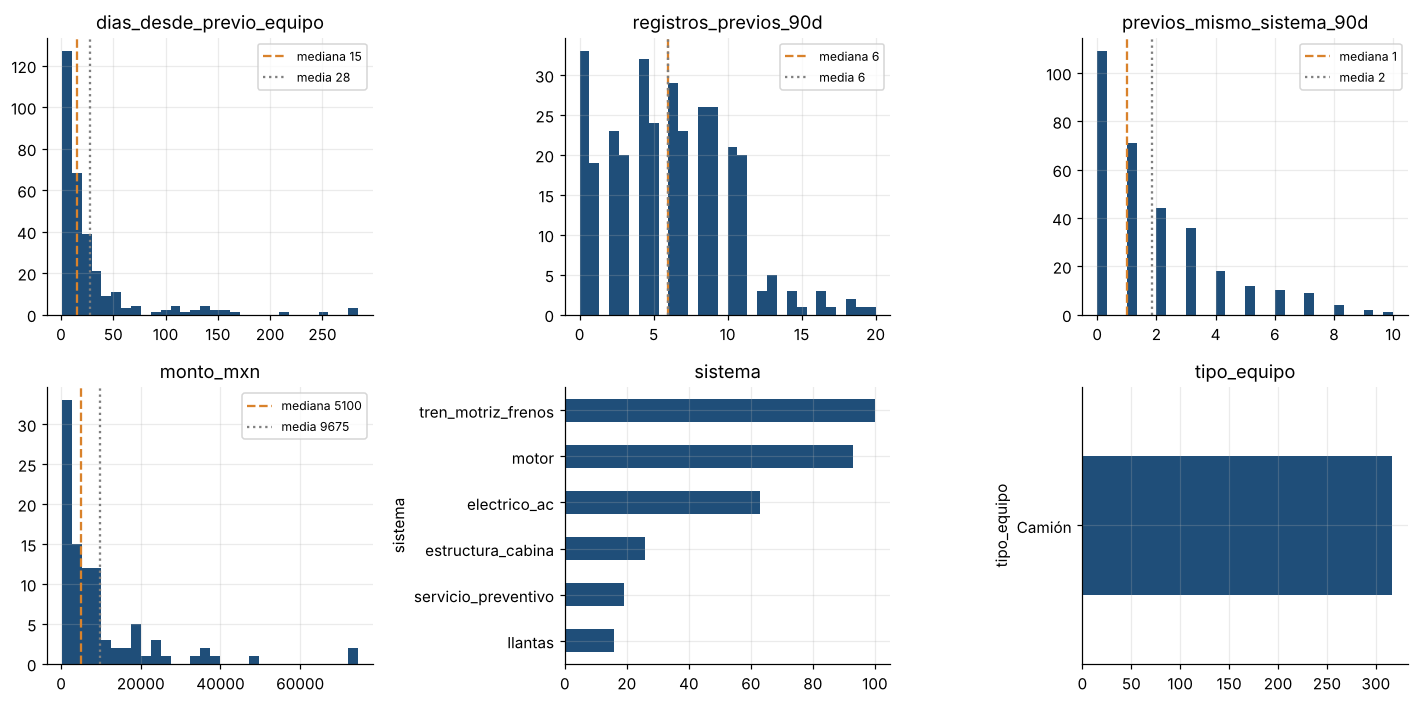

In [5]:
fig, ax = plt.subplots(2, 3, figsize=(13, 6.5))
for a, c in zip(ax.ravel()[:4], ['dias_desde_previo_equipo','registros_previos_90d','previos_mismo_sistema_90d','monto_mxn']):
    x = df[c].dropna(); a.hist(x, bins=30, color=AZ); a.axvline(x.median(), color=NA, ls='--', label=f'mediana {x.median():.0f}')
    a.axvline(x.mean(), color=GR, ls=':', label=f'media {x.mean():.0f}'); a.set_title(c); a.legend(fontsize=8)
df.sistema.value_counts().plot.barh(ax=ax[1,1], color=AZ); ax[1,1].set_title('sistema'); ax[1,1].invert_yaxis()
df.tipo_equipo.value_counts().plot.barh(ax=ax[1,2], color=AZ); ax[1,2].set_title('tipo_equipo'); ax[1,2].invert_yaxis()
plt.tight_layout(); plt.show()

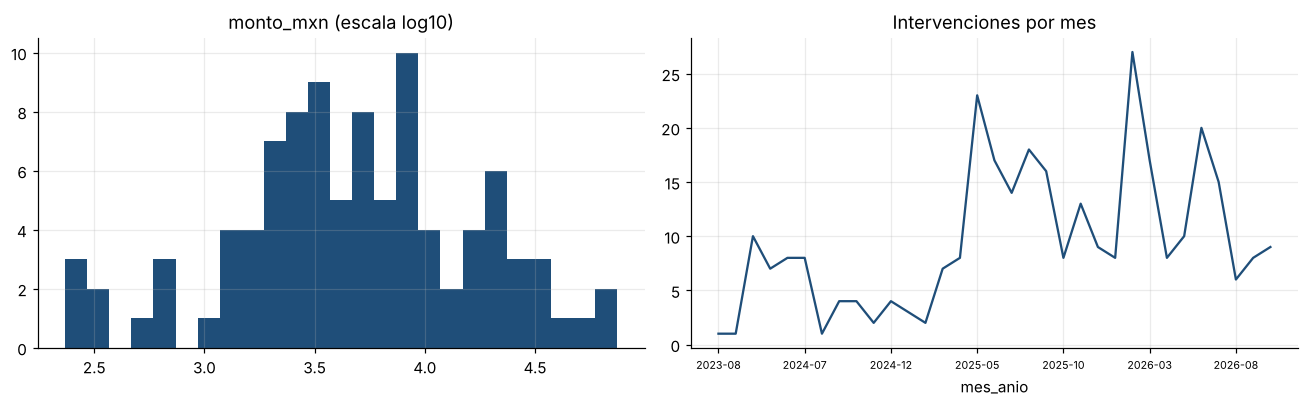

In [6]:
fig, ax = plt.subplots(1, 2, figsize=(12, 3.8))
x = np.log10(df.monto_mxn.dropna()); ax[0].hist(x, bins=25, color=AZ); ax[0].set_title('monto_mxn (escala log10)')
m = df.dropna(subset=['fecha']).copy(); m['mes_anio'] = pd.to_datetime(m.fecha).dt.to_period('M').astype(str)
m.groupby('mes_anio').size().plot(ax=ax[1], color=AZ); ax[1].set_title('Intervenciones por mes'); ax[1].tick_params(axis='x', labelsize=7)
plt.tight_layout(); plt.show()

**Lectura.** `monto_mxn` y `dias_desde_previo_equipo` están muy sesgadas a la derecha (media mayor que mediana): hay muchas intervenciones baratas/cercanas en el tiempo y pocas muy caras/espaciadas. En escala logarítmica `monto_mxn` se parece más a una campana, por lo que conviene usarla así. Los conteos de historial previo son discretos y también sesgados.

## 5. Correlación

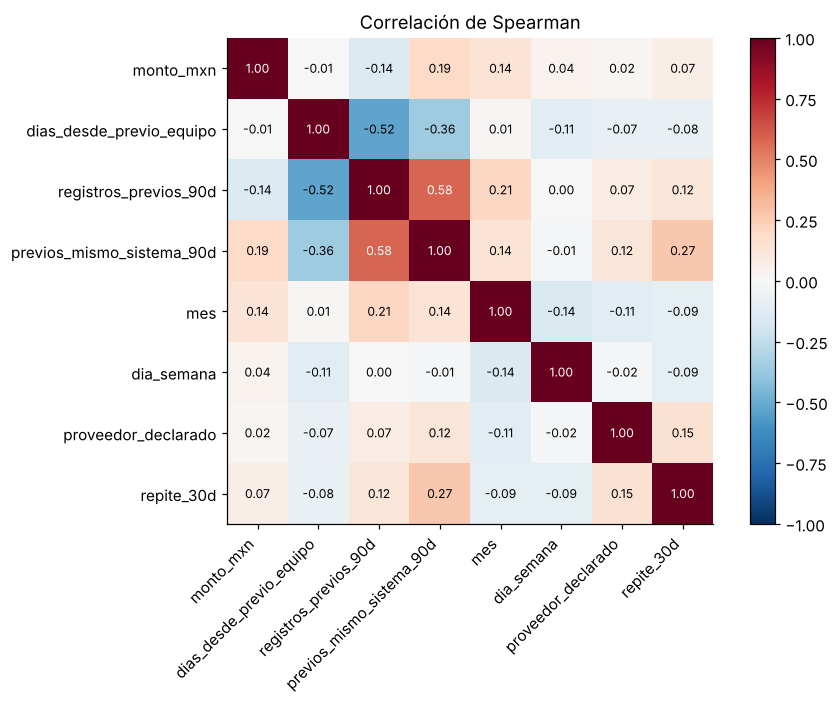

In [7]:
cols = ['monto_mxn','dias_desde_previo_equipo','registros_previos_90d','previos_mismo_sistema_90d','mes','dia_semana','proveedor_declarado','repite_30d']
cor = df[cols].astype(float).corr(method='spearman')
fig, a = plt.subplots(figsize=(8.5, 6.5))
im = a.imshow(cor, cmap='RdBu_r', vmin=-1, vmax=1)
a.set_xticks(range(len(cols))); a.set_xticklabels(cols, rotation=45, ha='right'); a.set_yticks(range(len(cols))); a.set_yticklabels(cols)
for i in range(len(cols)):
    for j in range(len(cols)):
        v = cor.iloc[i, j]
        if not np.isnan(v): a.text(j, i, f'{v:.2f}', ha='center', va='center', fontsize=8, color='white' if abs(v) > .55 else 'black')
a.grid(False); plt.colorbar(im, fraction=.046); a.set_title('Correlación de Spearman'); plt.tight_layout(); plt.show()

In [8]:
cor['repite_30d'].drop('repite_30d').sort_values(key=abs, ascending=False).round(3)

previos_mismo_sistema_90d    0.266
proveedor_declarado          0.150
registros_previos_90d        0.119
dia_semana                  -0.093
mes                         -0.087
dias_desde_previo_equipo    -0.078
monto_mxn                    0.068
Name: repite_30d, dtype: float64

**Lectura.** Se usa Spearman porque las variables son sesgadas. La señal más clara con el objetivo viene del historial reciente del equipo: más intervenciones previas del mismo sistema en 90 días (ρ ≈ 0.27) y más intervenciones del camión en los 90 días previos (ρ ≈ 0.12). El monto, el mes y el día de la semana casi no se relacionan con el objetivo.

## 6. Relación de las variables con el objetivo

In [9]:
lab = df[df.repite_30d.notna()].copy()
res = []
for c in ['sistema','equipo_id']:
    t = pd.crosstab(lab[c], lab.repite_30d); res.append((c, 'chi²', stats.chi2_contingency(t)[1]))
for c in ['dias_desde_previo_equipo','registros_previos_90d','previos_mismo_sistema_90d','monto_mxn','mes']:
    a, b = lab[lab.repite_30d == 1][c].dropna(), lab[lab.repite_30d == 0][c].dropna()
    res.append((c, 'Mann-Whitney', stats.mannwhitneyu(a, b).pvalue))
pd.DataFrame(res, columns=['variable','prueba','p-valor']).assign(significativa=lambda t: t['p-valor'] < .05).round(4)

,variable,prueba,p-valor,significativa
0,sistema,chi²,0.0000,True
1,equipo_id,chi²,0.3007,False
2,dias_desde_previo_equipo,Mann-Whitney,0.1997,False
3,registros_previos_90d,Mann-Whitney,0.0454,True
4,previos_mismo_sistema_90d,Mann-Whitney,0.0000,True
5,monto_mxn,Mann-Whitney,0.5353,False
6,mes,Mann-Whitney,0.1429,False


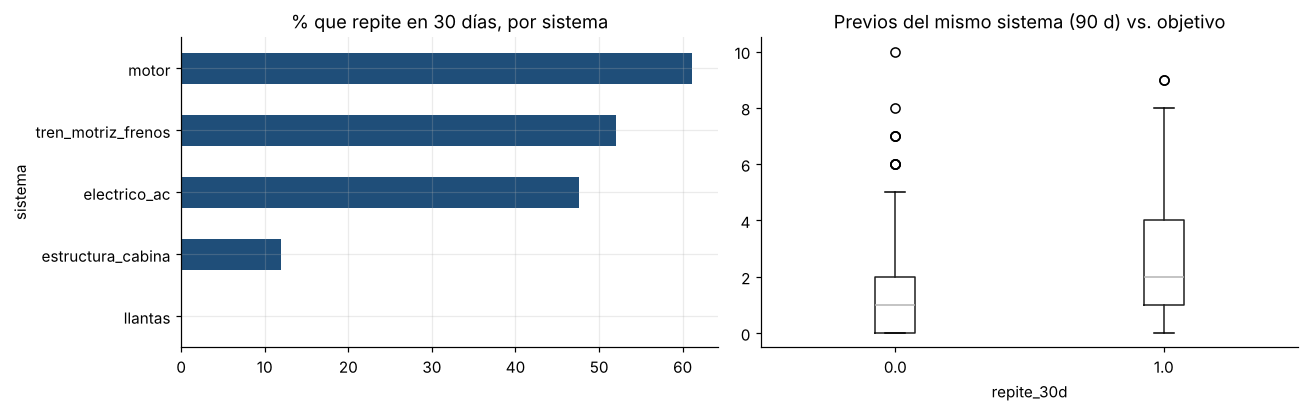

                    count   mean
sistema                         
electrico_ac           61  0.475
estructura_cabina      25  0.120
llantas                15  0.000
motor                  85  0.612
tren_motriz_frenos     98  0.520


In [10]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
(lab.groupby('sistema').repite_30d.mean().sort_values()*100).plot.barh(ax=ax[0], color=AZ); ax[0].set_title('% que repite en 30 días, por sistema')
lab.boxplot(column='previos_mismo_sistema_90d', by='repite_30d', ax=ax[1], grid=False); ax[1].set_title('Previos del mismo sistema (90 d) vs. objetivo'); plt.suptitle('')
plt.tight_layout(); plt.show()
print(lab.groupby('sistema').repite_30d.agg(['count','mean']).round(3))

**Lectura.** El sistema afectado es la variable más informativa: motor repite en ~61 % de los casos, tren motriz/frenos en ~52 % y eléctrico/A-C en ~48 %; estructura/cabina en ~12 % y llantas en 0 % (pocos casos, 15). El camión (C1 a C7) no muestra diferencia significativa. Los casos con más intervenciones previas del mismo sistema repiten más.

## 7. Valores nulos

In [11]:
nul = pd.DataFrame({'nulos': df.isna().sum(), '%': (100*df.isna().mean()).round(1)})
nul[nul.nulos > 0].sort_values('%', ascending=False)

,nulos,%
intervalo_servicio_h,309,97.5
monto_mxn,221,69.7
repite_30d,33,10.4
dias_desde_previo_equipo,11,3.5
fecha,1,0.3
dia_semana,1,0.3
mes,1,0.3
registros_previos_90d,1,0.3
previos_mismo_sistema_90d,1,0.3


| Variable | Nulos | Causa | Tratamiento propuesto |
|---|---|---|---|
| `monto_mxn` | ~70 % | La empresa no anota costo en la mayoría de las intervenciones | No imputar con un valor inventado. Crear indicador `monto_declarado` (sí/no) y usar el monto solo en el subconjunto que lo tiene; en modelos, imputación por mediana *por sistema* dentro del entrenamiento. |
| `intervalo_servicio_h` | ~97 % | Solo aplica a servicios preventivos | Excluir de las variables del modelo; los servicios no tienen objetivo. |
| `fecha` y derivadas (`mes`, `dia_semana`, historial) | <1 % (1 registro) | Anotaciones con solo el año | Dejar vacías; esas filas se excluyen del entrenamiento (no se inventa fecha). |
| `dias_desde_previo_equipo` | ~3.5 % | Primera intervención de cada equipo | Imputar con un valor grande (p. ej. 365) más indicador de “sin previo” (11 registros: primera intervención de cada camión). |
| `repite_30d` | ~10 % | Servicios, sin clasificar, sin fecha y últimos 30 días (censura) | Se excluyen del entrenamiento y la evaluación; no son negativos. |

## 8. Valores atípicos

In [12]:
def iqr(x):
    x = x.dropna(); q1, q3 = x.quantile([.25, .75]); i = q3 - q1; lo, hi = q1 - 1.5*i, q3 + 1.5*i
    return pd.Series({'n': len(x), 'atípicos': int(((x < lo) | (x > hi)).sum()), 'límite_sup': hi, 'máximo': x.max(), 'P99': x.quantile(.99)})
pd.DataFrame({c: iqr(df[c]) for c in ['monto_mxn','dias_desde_previo_equipo','registros_previos_90d','previos_mismo_sistema_90d']}).T.round(1)

,n,atípicos,límite_sup,máximo,P99
monto_mxn,96.0,11.0,22325.0,74500.0,74500.0
dias_desde_previo_equipo,306.0,29.0,61.0,284.0,252.7
registros_previos_90d,316.0,2.0,18.0,20.0,17.9
previos_mismo_sistema_90d,316.0,7.0,7.5,10.0,8.0


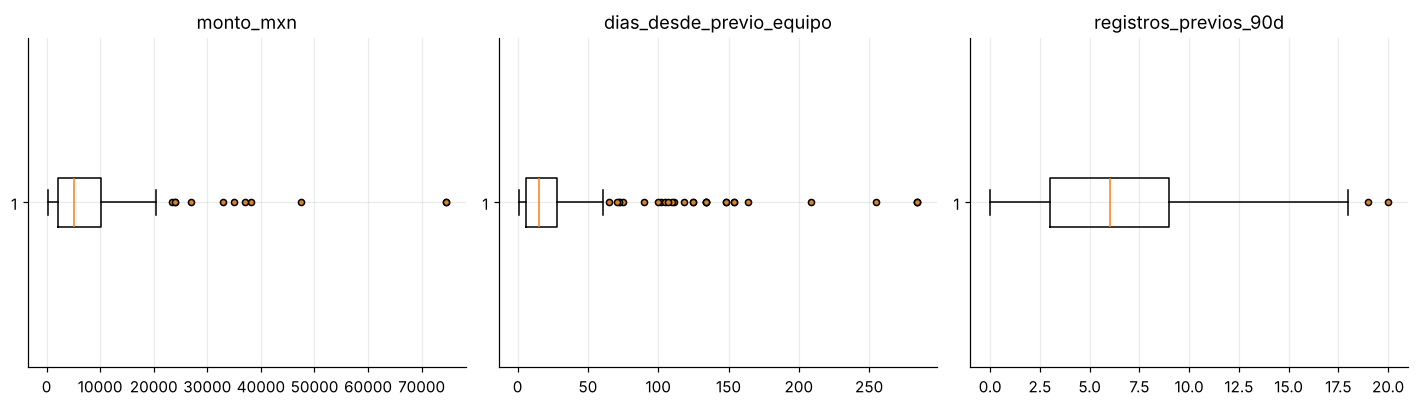

,fuente,equipo_id,fecha,sistema,monto_mxn
269,bitacora_camiones,C7,2025-03-25,estructura_cabina,74500.0
270,bitacora_camiones,C7,2025-03-25,motor,74500.0
147,bitacora_camiones,C5,2024-06-09,motor,47500.0
204,bitacora_camiones,C5,2026-06-01,motor,38225.0
221,bitacora_camiones,C6,2024-04-02,motor,37000.0


In [13]:
fig, ax = plt.subplots(1, 3, figsize=(13, 3.8))
for a, c in zip(ax, ['monto_mxn','dias_desde_previo_equipo','registros_previos_90d']):
    a.boxplot(df[c].dropna(), vert=False, flierprops=dict(marker='o', markerfacecolor=NA, markersize=4)); a.set_title(c)
plt.tight_layout(); plt.show()
df.nlargest(5, 'monto_mxn')[['fuente','equipo_id','fecha','sistema','monto_mxn']]

| Variable | Hallazgo | Tratamiento propuesto |
|---|---|---|
| `monto_mxn` | 11 atípicos por regla IQR (> ≈ $22,300); el máximo ($74,500, repartido entre motor y estructura de un mismo trabajo) es de C7 | No eliminar: son reparaciones mayores reales. Usar `log(1+monto)` y/o recortar en el percentil 99 solo para modelos sensibles a escala; reportar mediana. |
| `dias_desde_previo_equipo` | 29 por encima de ≈ 61 días | Son equipos con pocas fallas, no errores. Transformar con log y mantener. |
| Conteos de historial | Colas largas en equipos muy intensivos | Mantener; usar modelos basados en árboles o escalado robusto. |

Ningún valor atípico parece error de captura; se conservan y se tratan con transformaciones.

## 9. Conclusiones del Avance 1
- Hay **317** registros reales de los 7 camiones y 9 variables explicativas numéricas y categóricas; **284** tienen etiqueta para clasificación. El total queda por debajo de los 500 de la guía porque el alcance autorizado es solo camiones; la estructura del dataset permite sumar el resto de la flota cuando haya tiempo.
- El objetivo `repite_30d` está razonablemente balanceado (~48 % positivos), lo que facilita el modelado.
- Las variables más útiles son el **sistema** y el **historial reciente** del mismo sistema; monto y mes aportan poco.
- Limitaciones: pocos datos (317), el monto falta en ~70 % y el costo declarado se reparte entre sistemas cuando un trabajo toca varios.
- Siguiente paso: entrenar y comparar clasificadores (Naive Bayes, KNN, árbol de decisión) con validación temporal y reportar matriz de confusión, precisión, recall y F1.

---
# Avance 2
## 10. Preprocesamiento e ingeniería de características
Aquí aplicamos lo que dejamos propuesto en el Avance 1 (secciones 7 y 8). Trabajamos solo con los registros que tienen el objetivo `repite_30d` conocido (284) y fecha válida. Se quitan los servicios preventivos, los de fecha desconocida y los de los últimos 30 días, porque no sabemos si se repetirán y tratarlos como "no" sería inventar.

El preprocesamiento tiene tres partes: (1) **ingeniería de características**, que son cuentas fila por fila sin mirar otras filas, (2) **imputación**, y (3) **escalamiento y One-Hot**. Las partes 2 y 3 se dejan dentro de un `Pipeline` para que se aprendan solo con los datos de entrenamiento y no se filtre información del conjunto de prueba.

In [14]:
from sklearn.base import BaseEstimator, TransformerMixin, clone
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

lab = df[df.repite_30d.notna() & df.fecha.notna()].copy()
lab['fecha'] = pd.to_datetime(lab.fecha)
lab = lab.sort_values('fecha').reset_index(drop=True)
lab['repite_30d'] = lab.repite_30d.astype(int)
print(f'Registros para modelar: {len(lab)}  |  repite en 30 días: {lab.repite_30d.mean():.1%}')

def ingenieria(d):
    """Variables derivadas, fila por fila (no usan información de otras filas)."""
    x = pd.DataFrame(index=d.index)
    x['sistema'], x['equipo_id'] = d.sistema, d.equipo_id
    x['mes'], x['dia_semana'] = d.mes, d.dia_semana
    x['sin_previo'] = d.dias_desde_previo_equipo.isna().astype(int)          # primera intervención del camión
    x['dias_log'] = np.log1p(d.dias_desde_previo_equipo.fillna(365))         # sesgo a la derecha -> logaritmo
    x['registros_previos_90d'] = d.registros_previos_90d
    x['previos_mismo_sistema_90d'] = d.previos_mismo_sistema_90d
    x['monto_declarado'] = d.monto_mxn.notna().astype(int)                   # el monto falta en ~70 %: se marca
    x['monto_log'] = np.log1p(d.monto_mxn)
    x['pieza_declarada'], x['proveedor_declarado'] = d.pieza_declarada, d.proveedor_declarado
    return x

class ImputaMontoPorSistema(BaseEstimator, TransformerMixin):
    """Rellena el monto faltante con la mediana del sistema, calculada solo con el conjunto de entrenamiento."""
    def fit(self, X, y=None):
        self.global_ = X.monto_log.median()
        self.por_sistema_ = X.groupby('sistema').monto_log.median().to_dict()
        return self
    def transform(self, X):
        X = X.copy()
        X['monto_log'] = X.monto_log.fillna(X.sistema.map(self.por_sistema_)).fillna(self.global_)
        return X

NUM = ['mes', 'dia_semana', 'dias_log', 'registros_previos_90d', 'previos_mismo_sistema_90d', 'monto_log']
BIN = ['sin_previo', 'monto_declarado', 'pieza_declarada', 'proveedor_declarado']
CAT = ['sistema', 'equipo_id']

def preproceso():
    ct = ColumnTransformer([
        ('num', Pipeline([('imputar', SimpleImputer(strategy='median')), ('escalar', StandardScaler())]), NUM),
        ('bin', 'passthrough', BIN),
        ('cat', OneHotEncoder(handle_unknown='ignore', sparse_output=False), CAT)])
    return Pipeline([('monto', ImputaMontoPorSistema()), ('ct', ct)])

X, y = ingenieria(lab), lab.repite_30d
print('Variables de entrada:', X.shape[1])
X.head()

Registros para modelar: 284  |  repite en 30 días: 47.5%
Variables de entrada: 12


,sistema,equipo_id,mes,dia_semana,sin_previo,dias_log,registros_previos_90d,previos_mismo_sistema_90d,monto_declarado,monto_log,pieza_declarada,proveedor_declarado
0,tren_motriz_frenos,C1,8.0,4.0,1,5.902633,0.0,0.0,0,NaN,0,0
1,motor,C6,3.0,3.0,1,5.902633,0.0,0.0,0,NaN,0,0
2,motor,C6,4.0,1.0,0,1.791759,1.0,1.0,1,10.5187,0,1
3,estructura_cabina,C1,4.0,0.0,0,5.545177,0.0,0.0,0,NaN,0,0
4,estructura_cabina,C7,4.0,1.0,1,5.902633,0.0,0.0,0,NaN,0,0


| Variable | Tipo | Nulos antes | Tratamiento |
|---|---|---|---|
| `dias_log` (de `dias_desde_previo_equipo`) | numérica | 3.5 % (10 registros) | Los nulos son la primera intervención de cada camión: se rellenan con 365 días y se marcan con `sin_previo`; luego logaritmo y estandarización. |
| `monto_log` (de `monto_mxn`) | numérica | ~70 % | `monto_declarado` indica si hay monto; los faltantes se imputan con la mediana de su sistema (calculada solo con entrenamiento); logaritmo y estandarización. |
| `mes`, `dia_semana`, `registros_previos_90d`, `previos_mismo_sistema_90d` | numéricas | 0 % | Estandarización (media 0, desviación 1), con imputación por mediana como respaldo. |
| `pieza_declarada`, `proveedor_declarado`, `sin_previo`, `monto_declarado` | binarias | 0 % | Se dejan como están. |
| `sistema` (5 grupos), `equipo_id` (7 camiones) | categóricas | 0 % | Codificación One-Hot. |

In [15]:
# Nulos de las variables originales (antes de imputar), entre los 284 registros que se van a modelar
brutas = lab[['dias_desde_previo_equipo', 'monto_mxn', 'mes', 'dia_semana', 'registros_previos_90d', 'previos_mismo_sistema_90d']]
nulos_antes = pd.DataFrame({'nulos': brutas.isna().sum(), '%': (100*brutas.isna().mean()).round(1)}); nulos_antes

,nulos,%
dias_desde_previo_equipo,10,3.5
monto_mxn,199,70.1
mes,0,0.0
dia_semana,0,0.0
registros_previos_90d,0,0.0
previos_mismo_sistema_90d,0,0.0


In [16]:
# Qué sale del preprocesamiento (ajustado con todo el conjunto solo para mostrarlo; en el modelo se ajusta únicamente con entrenamiento)
demo = preproceso().fit(X)
Z = demo.transform(X)
nombres = [n.split('__')[-1] for n in demo.named_steps['ct'].get_feature_names_out()]
Zdf = pd.DataFrame(Z, columns=nombres)
print(f'Matriz de {Z.shape[0]} filas x {Z.shape[1]} columnas | nulos después: {int(np.isnan(Z).sum())}')
Zdf[NUM].describe().loc[['mean','std','min','max']].round(2)

Matriz de 284 filas x 22 columnas | nulos después: 0


,mes,dia_semana,dias_log,registros_previos_90d,previos_mismo_sistema_90d,monto_log
mean,0.00,0.00,-0.00,0.00,0.00,0.00
std,1.00,1.00,1.00,1.00,1.00,1.00
min,-1.76,-1.32,-1.69,-1.42,-0.88,-3.59
max,2.09,2.71,2.45,3.35,3.75,3.44


Después del preprocesamiento no queda ningún nulo, las numéricas tienen media cercana a 0 y desviación de 1, y las categóricas pasaron a 12 columnas One-Hot (5 sistemas y 7 camiones). En total son 22 columnas.

## 11. Partición de datos
Los registros son una línea de tiempo: lo que pasó en abril no se puede usar para predecir marzo. Por eso el corte principal es **temporal, 80/20**: entrenamos con el 80 % más antiguo y probamos con el 20 % más reciente. Para ajustar los hiperparámetros usamos validación cruzada **temporal** (`TimeSeriesSplit`, 5 pliegues) dentro del conjunto de entrenamiento. Como contraste, al final también reportamos un K-Fold estratificado de 5 pliegues con los datos mezclados.

In [17]:
n_ent = int(len(lab) * 0.8)
Xe, Xp, ye, yp = X.iloc[:n_ent], X.iloc[n_ent:], y.iloc[:n_ent], y.iloc[n_ent:]
part = pd.DataFrame({'registros': [len(Xe), len(Xp)],
                     'desde': [lab.fecha.iloc[0].date(), lab.fecha.iloc[n_ent].date()],
                     'hasta': [lab.fecha.iloc[n_ent-1].date(), lab.fecha.iloc[-1].date()],
                     '% que repite': [round(100*ye.mean(), 1), round(100*yp.mean(), 1)]}, index=['Entrenamiento (80 %)', 'Prueba (20 %)'])
part

,registros,desde,hasta,% que repite
Entrenamiento (80 %),227,2023-08-04,2026-04-14,42.7
Prueba (20 %),57,2026-04-14,2026-09-07,66.7


Ojo con la última columna: en el periodo de entrenamiento se repite el 43 % de los casos y en el de prueba el 67 %. El taller tuvo más actividad en los últimos meses, así que la prueba es más exigente que un corte aleatorio. Lo tomamos en cuenta al leer los resultados.

## 12. Entrenamiento de cuatro modelos de la Unidad 3
Entrenamos **Naive Bayes, KNN, SVM con núcleo RBF y un árbol de decisión**, todos dentro de un `Pipeline` con el preprocesamiento de la sección 10. Los hiperparámetros se escogen con `GridSearchCV` sobre el conjunto de entrenamiento (validación temporal de 5 pliegues, métrica F1). Añadimos dos referencias que no aprenden nada: predecir siempre la clase más frecuente y predecir siempre que sí se repite. Cualquier modelo útil tiene que superarlas.

In [18]:
from sklearn.dummy import DummyClassifier
from sklearn.model_selection import GridSearchCV, TimeSeriesSplit
from sklearn.naive_bayes import GaussianNB
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, confusion_matrix

espacios = {
 'Naive Bayes':       (GaussianNB(),                                    {'m__var_smoothing': [1e-9, 1e-6, 1e-3, 1e-1]}),
 'KNN':               (KNeighborsClassifier(),                          {'m__n_neighbors': [3, 5, 7, 11, 15], 'm__weights': ['uniform', 'distance']}),
 'SVM (RBF)':         (SVC(kernel='rbf', probability=True, random_state=0), {'m__C': [0.1, 1, 10], 'm__gamma': ['scale', 0.01, 0.1]}),
 'Árbol de decisión': (DecisionTreeClassifier(random_state=0),          {'m__max_depth': [2, 3, 4, 5], 'm__min_samples_leaf': [5, 10, 20]})}
cv = TimeSeriesSplit(n_splits=5)
mejores = {}
for nombre, (modelo, grid) in espacios.items():
    gs = GridSearchCV(Pipeline([('prep', preproceso()), ('m', modelo)]), grid, cv=cv, scoring='f1').fit(Xe, ye)
    mejores[nombre] = gs
    print(f'{nombre:18s} F1 en validación cruzada = {gs.best_score_:.3f}   mejores hiperparámetros: {gs.best_params_}')

Naive Bayes        F1 en validación cruzada = 0.631   mejores hiperparámetros: {'m__var_smoothing': 1e-09}


KNN                F1 en validación cruzada = 0.364   mejores hiperparámetros: {'m__n_neighbors': 7, 'm__weights': 'distance'}


SVM (RBF)          F1 en validación cruzada = 0.343   mejores hiperparámetros: {'m__C': 10, 'm__gamma': 'scale'}


Árbol de decisión  F1 en validación cruzada = 0.403   mejores hiperparámetros: {'m__max_depth': 3, 'm__min_samples_leaf': 5}


## 13. Tabla comparativa de rendimiento preliminar
Cada modelo se evalúa con las 57 filas de prueba que nunca vio. Reportamos Accuracy, Precision, Recall y F1 (la clase positiva es "se repite en 30 días"), más el AUC, que no depende del umbral de 0.5, y el F1 medio de la validación cruzada de entrenamiento.

In [19]:
filas = {}
for nombre, gs in mejores.items():
    p, pr = gs.predict(Xp), gs.predict_proba(Xp)[:, 1]
    filas[nombre] = dict(Accuracy=accuracy_score(yp, p), Precision=precision_score(yp, p, zero_division=0), Recall=recall_score(yp, p, zero_division=0),
                         F1=f1_score(yp, p, zero_division=0), AUC=roc_auc_score(yp, pr), **{'F1 en validación cruzada': gs.best_score_})
for nombre, est in {'Referencia: clase más frecuente': DummyClassifier(strategy='most_frequent'),
                    'Referencia: siempre "repite"': DummyClassifier(strategy='constant', constant=1)}.items():
    p = est.fit(Xe, ye).predict(Xp)
    filas[nombre] = dict(Accuracy=accuracy_score(yp, p), Precision=precision_score(yp, p, zero_division=0), Recall=recall_score(yp, p, zero_division=0),
                         F1=f1_score(yp, p, zero_division=0), AUC=0.5, **{'F1 en validación cruzada': np.nan})
tabla = pd.DataFrame(filas).T
tabla.round(3)

,Accuracy,Precision,Recall,F1,AUC,F1 en validación cruzada
Naive Bayes,0.772,0.745,1.000,0.854,0.609,0.631
KNN,0.596,0.778,0.553,0.646,0.699,0.364
SVM (RBF),0.368,0.600,0.158,0.250,0.476,0.343
Árbol de decisión,0.404,0.833,0.132,0.227,0.603,0.403
Referencia: clase más frecuente,0.333,0.000,0.000,0.000,0.500,NaN
"Referencia: siempre ""repite""",0.667,0.667,1.000,0.800,0.500,NaN


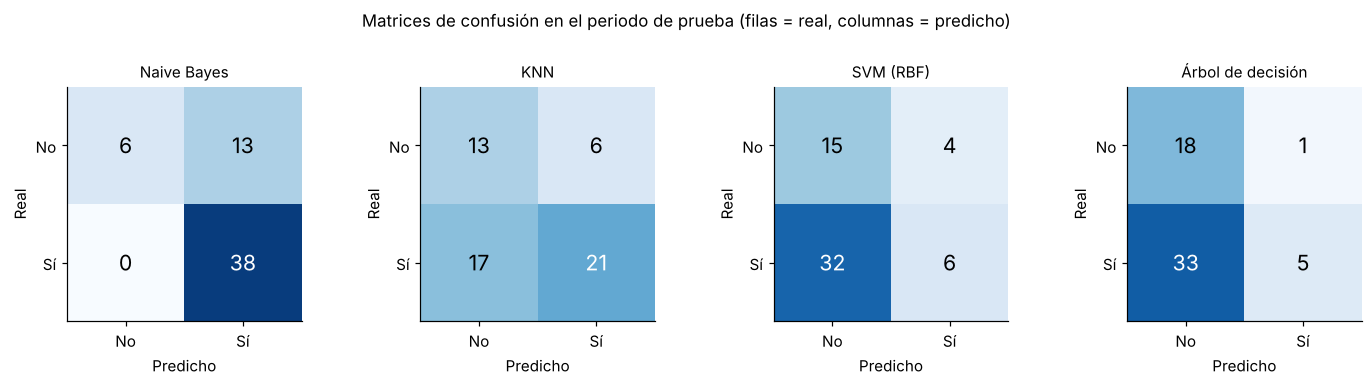

In [20]:
fig, ax = plt.subplots(1, 4, figsize=(13, 3.2))
for a, nombre in zip(ax, mejores):
    cm = confusion_matrix(yp, mejores[nombre].predict(Xp))
    a.imshow(cm, cmap='Blues', vmin=0, vmax=40); a.set_title(nombre, fontsize=10); a.grid(False)
    for i in range(2):
        for j in range(2): a.text(j, i, cm[i, j], ha='center', va='center', fontsize=14, color='white' if cm[i, j] > 20 else 'black')
    a.set_xticks([0, 1]); a.set_yticks([0, 1]); a.set_xticklabels(['No', 'Sí']); a.set_yticklabels(['No', 'Sí']); a.set_xlabel('Predicho'); a.set_ylabel('Real')
plt.suptitle('Matrices de confusión en el periodo de prueba (filas = real, columnas = predicho)', y=1.04, fontsize=11); plt.tight_layout(); plt.show()

In [21]:
from sklearn.model_selection import StratifiedKFold, cross_validate
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
kf = {}
for nombre, gs in mejores.items():
    r = cross_validate(clone(gs.best_estimator_), X, y, cv=skf, scoring=['accuracy', 'precision', 'recall', 'f1'])
    kf[nombre] = {m.capitalize(): f"{r['test_'+m].mean():.3f} ± {r['test_'+m].std():.3f}" for m in ['accuracy', 'precision', 'recall', 'f1']}
base_kf = cross_validate(DummyClassifier(strategy='constant', constant=1), X, y, cv=skf, scoring=['accuracy', 'precision', 'recall', 'f1'])
kf['Referencia: siempre "repite"'] = {m.capitalize(): f"{base_kf['test_'+m].mean():.3f} ± {base_kf['test_'+m].std():.3f}" for m in ['accuracy', 'precision', 'recall', 'f1']}
pd.DataFrame(kf).T

,Accuracy,Precision,Recall,F1
Naive Bayes,0.595 ± 0.030,0.541 ± 0.016,0.978 ± 0.030,0.697 ± 0.020
KNN,0.591 ± 0.035,0.580 ± 0.050,0.563 ± 0.064,0.566 ± 0.021
SVM (RBF),0.595 ± 0.023,0.568 ± 0.021,0.622 ± 0.092,0.591 ± 0.046
Árbol de decisión,0.567 ± 0.027,0.572 ± 0.074,0.593 ± 0.262,0.532 ± 0.136
"Referencia: siempre ""repite""",0.475 ± 0.003,0.475 ± 0.003,1.000 ± 0.000,0.644 ± 0.003


La tabla de arriba es el resultado principal (corte temporal). La de abajo es el **contraste con K-Fold estratificado de 5 pliegues** (media ± desviación) con los datos mezclados, tal como lo permite el enunciado. Se ve mejor en algunos modelos porque cada pliegue de prueba tiene registros de todas las épocas, y por eso la damos solo como referencia: con datos en el tiempo, el corte temporal es el que representa el uso real.

**Lectura de resultados (honesta).**

- **Naive Bayes** es el mejor por F1 (0.85 en prueba, 0.63 en validación cruzada), pero hay que leerlo con cuidado: detecta las 38 repeticiones reales (recall = 1.0) marcando casi todo como "se repite" (solo acierta 6 de 19 casos que no se repiten). La referencia de "siempre se repite" ya logra F1 = 0.80, así que la ganancia real es pequeña. En el K-Fold, su F1 (0.70) tampoco se aleja mucho de esa referencia (0.64).
- **KNN** es el más equilibrado: Precision de 0.78, Recall de 0.55 y el AUC más alto (0.70). Se queda por debajo de las referencias en F1 (0.65), pero acierta más cuando dice que sí.
- **SVM y el árbol de decisión** no generalizan al periodo reciente: con F1 de 0.25 y 0.23, casi siempre predicen "no se repite", porque aprendieron de un periodo en el que se repetía menos. Se defienden mejor en el K-Fold (F1 de 0.59 y 0.53), lo que confirma que el problema es el cambio de proporción en el tiempo y no solo el modelo.
- En general, **las señales son débiles**: con 284 registros y variables de historial reciente, ningún modelo supera con claridad a la referencia. Es un resultado preliminar y lo decimos tal cual.

## 14. Conclusiones del Avance 2 y siguientes pasos
- Preprocesamos el dataset sin dejar nulos: imputación (mediana por sistema para el monto y 365 días con indicador para el primer registro), logaritmo en las variables sesgadas, estandarización de las numéricas y One-Hot de las categóricas, todo dentro de un `Pipeline` para evitar fugas de información.
- Partimos los datos en el tiempo (80/20) y validamos con `TimeSeriesSplit`; el K-Fold estratificado queda como contraste.
- Entrenamos cuatro modelos de la Unidad 3 con búsqueda de hiperparámetros y los comparamos con Accuracy, Precision, Recall, F1 y AUC, además de dos referencias.
- **Modelo preliminar: Naive Bayes** (mejor F1 en validación y en prueba), con la advertencia de que apenas supera a la referencia. KNN es la alternativa más balanceada.
- Para el Proyecto Integrador: ajustar el umbral de decisión y probar pesos por clase, agregar una variable de actividad reciente de toda la flota para capturar el cambio de proporción, revisar los errores caso por caso (qué sistemas y camiones se confunden), calibrar las probabilidades y elegir el mejor modelo con matriz de confusión y análisis de errores.
- Límites: 284 registros (por debajo de los 500 de la guía, por el alcance autorizado de solo camiones), monto declarado en ~30 % de los casos y un cambio de proporción entre el periodo de entrenamiento y el de prueba. Cuando haya más equipos y registros se podrá repetir el mismo cuaderno sin cambiar el código.